# LAB 04 — Earth as an Exoplanet: PSG spektri
**Astrobiologija**  
**Ime i prezime:** Sofija Stefanovic  **Indeks:** 181/2022

> **Istraživačko pitanje:** Kako prepoznajemo atmosferske karakteristike Zemlje iz reflektovane svetlosti ili termalne emisije?

**Pravila rada:** Realne modele generišete u **NASA Planetary Spectrum Generator (PSG)**, a u ovom notebooku proveravate konfiguracije, čitate stvarne ASCII izlaze, crtate i tumačite spektre. Demonstracioni račun ili grafik u Pythonu **nije PSG simulacija**. **Ne izmišljajte podatke ako server nije dostupan**


In [1]:
from pathlib import Path
import io, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
print('Radni folder:', Path.cwd())
print('PSG datoteke u data/:', [p.name for p in DATA_DIR.iterdir() if p.is_file()])

Radni folder: /home/sofija/Desktop/Astrobiologija/4
PSG datoteke u data/: ['earth_variant.cfg', 'earth_ref.cfg', 'earth_variant.txt', 'earth_ref.txt']


In [2]:
def inspect_psg_ascii(path, preview_lines=35):
    """Prikazuje originalno zaglavlje i učitava samo numeričke redove.
    Ne nagađa imena kolona ni fizičke jedinice.
    """
    path = Path(path)
    lines = path.read_text(encoding='utf-8-sig', errors='replace').splitlines()
    print(f'Fajl: {path.name}; ukupno redova: {len(lines)}')
    print('--- PRVI REDOVI ---')
    print('\n'.join(lines[:preview_lines]))
    rows = []
    for line in lines:
        line = line.strip()
        if not line or line.startswith('#') or line.startswith('<'):
            continue
        parts = line.split()
        try:
            row = [float(v.replace('D','E').replace('d','e')) for v in parts]
        except ValueError:
            continue
        if all(np.isfinite(row)):
            rows.append(row)
    if not rows:
        raise ValueError('Nema prepoznatih numeričkih redova; pogledajte originalni fajl.')
    widths = {len(row) for row in rows}
    if len(widths) != 1:
        raise ValueError(f'Neujednačen broj numeričkih kolona {widths}; potreban ručni pregled.')
    df = pd.DataFrame(rows, columns=[f'col_{i}' for i in range(len(rows[0]))])
    print('--- DIMENZIJE ---', df.shape)
    display(df.head())
    return df, lines

# Primer za primenu kada student ima stvaran PSG izlaz:
# df_ref, header_ref = inspect_psg_ascii(DATA_DIR / 'earth_ref.txt')

In [3]:
def plot_selected_columns(df, x_col, y_col, xlabel, ylabel, title='PSG ASCII — korisnički izbor kolona'):
    if x_col not in df or y_col not in df:
        raise KeyError('Izabrana kolona nije u tabeli.')
    x = df[x_col].to_numpy(float)
    y = df[y_col].to_numpy(float)
    order = np.argsort(x)
    fig, ax = plt.subplots(figsize=(10,4))
    ax.plot(x[order], y[order], lw=1.4)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(alpha=.25)
    plt.show()

# Poziv nakon pregleda zaglavlja, npr.:
# plot_selected_columns(df_ref, 'col_0', 'col_1',
#     'Talasna dužina [µm] — provereno iz zaglavlja',
#     'Fizička jedinica iz zaglavlja', 'PSG Earth — referenca')

In [4]:
def wavenumber_to_micron(sigma_cm_inv):
    sigma = np.asarray(sigma_cm_inv, dtype=float)
    if np.any(sigma <= 0):
        raise ValueError('Talasni broj mora biti pozitivan.')
    return 1e4 / sigma

print('Primer transformacije KOORDINATE (ne PSG podatak):',
      wavenumber_to_micron([1000, 2000]), 'µm')

Primer transformacije KOORDINATE (ne PSG podatak): [10.  5.] µm


In [5]:
from difflib import unified_diff

def compare_cfg(path_reference, path_variant):
    a = Path(path_reference).read_text(encoding='utf-8-sig', errors='replace').splitlines()
    b = Path(path_variant).read_text(encoding='utf-8-sig', errors='replace').splitlines()
    changes = list(unified_diff(a, b, fromfile='REFERENCE', tofile='VARIANT', lineterm=''))
    print('\n'.join(changes) if changes else 'Fajlovi su tekstualno identični.')
    return changes

# compare_cfg(DATA_DIR/'earth_ref.cfg', DATA_DIR/'earth_variant.cfg')

# III. Studentski rad 
## Zadatak 1 - Identifikacija posmatračkog režima

1. Svojim rečima objasnite **reflektovanu svetlost, termalnu emisiju, transmisiju i tranzit / sekundarni eklips**. Izaberite jedan režim za svoj model i objasnite zašto.
2. Navedite šta predstavlja osa x, šta osa y i šta bi bilo potrebno za izračunavanje planet–zvezda kontrasta.
3. Ocenite koje osobine atmosfere i površine vaš režim može otkriti i koja su ograničenja.
4. Navedite dva razloga zašto apsorpciona osobina nije neposredan dokaz biosignature.

**Predajte:** odgovor od 120–180 reči.

**Odgovor studenta — Zadatak 1:**

**Režimi.** Reflektovana svetlost je zvezdana svetlost koju planeta rasejava i odbija; zavisi od albeda, oblaka, površine i faznog ugla. Termalna emisija je sopstveno infracrveno zračenje planete; zavisi od temperature, opaciteta i visine sa koje zračenje izlazi. Transmisija se meri tokom tranzita, kada svetlost zvezde prolazi kroz atmosferu na terminatoru. Sekundarni eklips je pad fluksa sistema kada planeta zađe iza zvezde, pa razlika daje fluks dnevne strane planete.

**Izbor.** Biram termalnu emisiju u srednjem IR-u, jer taj opseg sadrži CO₂ (15 µm), O₃ (9,6 µm) i H₂O, a signal ne zavisi od albeda.

**Ose.** Osa x je talasna dužina u µm, osa y radijansa ili fluks u jedinicama iz zaglavlja. Za kontrast planeta–zvezda potrebni su i spektar zvezde u istim jedinicama, odnos $(R_p/R_\star)^2$ i geometrija.

**Mogućnosti i ograničenja.** Režim otkriva temperaturu, sastav i opacitet, ali ne i detalje površine; ograničavaju ga oblaci i degeneracija temperaturnog profila i abundanci.

**Biosignature.** (1) Isti gas može nastati abiotički (npr. O₃/O₂ fotohemijom). (2) Pojas se preklapa sa drugim gasovima i zavisi od temperaturnog profila i oblaka.

## Zadatak 2 - Kreiranje Earth konfiguracije u PSG-u

Otvorite [PSG](https://psg.gsfc.nasa.gov/). Iskoristite **Earth** template i: *Load template → Object/Geometry → Atmosphere → Instrument → Save settings → Download configuration*.

1. Proverite i zapišite ime objekta, izvor svetlosti, posmatrača, udaljenost, fazu i (gde se primenjuje) uglove osvetljenja i posmatranja.
2. Izaberite **jedan** instrument/opseg odgovarajući vašem režimu. Za termalni IR nastavnik može odobriti provereni srednji IR instrument ili idealizovani $R$ sa opsegom koji sadrži približno 9,6 i 15 µm. Izbor stvarnog JWST instrumenta mora odgovarati geometriji.
3. Proverite referentni atmosferski model, prisustvo CO₂, O₃ i H₂O, površinsku temperaturu i da li postoje oblaci.
4. Sačuvajte originalni fajl kao `earth_ref.cfg`; ne oslanjajte se samo na sliku ekrana.
5. Uključite podatke o izvoru template-a, datumu generisanja, verziji ili adresi PSG interfejsa i relevantna podešavanja.

**Predajte:** `.cfg` i tabelu ključnih parametara.

In [6]:
# ZADATAK 2 — pregled/reference .cfg parametara
def parse_cfg(path):
    """Čita PSG .cfg (<KEY>value). Za ponovljene ključeve čuva sve vrednosti, redom."""
    out = {}
    for line in Path(path).read_text(encoding='utf-8-sig', errors='replace').splitlines():
        m = re.match(r'\s*<([^>]+)>(.*)$', line)
        if m:
            out.setdefault(m.group(1).strip(), []).append(m.group(2).strip())
    return out

def cfg_table(path, prefixes=('OBJECT', 'GEOMETRY', 'ATMOSPHERE', 'SURFACE', 'GENERATOR'), maxlen=70):
    rows = []
    for k, vals in parse_cfg(path).items():
        if k.startswith(prefixes):
            v = ' | '.join(vals)
            rows.append({'ključ': k, 'vrednost': v if len(v) <= maxlen else v[:maxlen] + '…',
                         'br. ponavljanja': len(vals)})
    return pd.DataFrame(rows)

CFG_REF = DATA_DIR / 'earth_ref.cfg'
if not CFG_REF.exists():
    print('Nema data/earth_ref.cfg — generišite ga u PSG-u (Zadatak 2) i stavite u data/.')
else:
    tab_ref = cfg_table(CFG_REF)
    pd.set_option('display.max_rows', 200, 'display.max_colwidth', 90)
    display(tab_ref)

    # Kontrolna lista: šta se mora proveriti i zapisati (traže se podniske u imenima ključeva)
    cfg_ref = parse_cfg(CFG_REF)
    checks = {'objekat/ime': 'OBJECT-NAME', 'datum': 'OBJECT-DATE', 'faza': 'PHASE',
              'udaljenost': 'DISTANCE', 'opseg': 'RANGE', 'rezolucija': 'RESOLUTION',
              'jedinice izlaza': 'RADUNITS', 'gasovi': 'ATMOSPHERE-GAS', 'abundance': 'ATMOSPHERE-ABUN',
              'pritisak': 'PRESSURE', 'površ. temperatura': 'SURFACE-TEMPERATURE', 'oblaci/aerosoli': 'AERO'}
    print('\n--- KONTROLNA LISTA ---')
    for label, sub in checks.items():
        hits = {k: ' | '.join(v)[:60] for k, v in cfg_ref.items() if sub in k}
        print(f'{label:22s}', hits if hits else 'NIJE PRONAĐENO — proverite u PSG GUI-ju')

    gas_txt = ' '.join(cfg_ref.get('ATMOSPHERE-GAS', []))
    for g in ['CO2', 'O3', 'H2O']:
        print(f'Gas {g} u ATMOSPHERE-GAS:', g in gas_txt)

,ključ,vrednost,br. ponavljanja
0,OBJECT,Planet,1
1,OBJECT-NAME,Earth,1
2,OBJECT-DATE,2017/09/14 15:10,1
3,OBJECT-DIAMETER,12742,1
4,OBJECT-GRAVITY,9.807,1
5,OBJECT-GRAVITY-UNIT,g,1
6,OBJECT-STAR-DISTANCE,1.0058,1
7,OBJECT-STAR-VELOCITY,-0.4526,1
8,OBJECT-SOLAR-LONGITUDE,311.4,1
9,OBJECT-SOLAR-LATITUDE,3.20,1



--- KONTROLNA LISTA ---
objekat/ime            {'OBJECT-NAME': 'Earth'}
datum                  {'OBJECT-DATE': '2017/09/14 15:10'}
faza                   NIJE PRONAĐENO — proverite u PSG GUI-ju
udaljenost             {'OBJECT-STAR-DISTANCE': '1.0058', 'GEOMETRY-STAR-DISTANCE': '-1.000000e+00'}
opseg                  {'GENERATOR-RANGE1': '5', 'GENERATOR-RANGE2': '20', 'GENERATOR-RANGEUNIT': 'um'}
rezolucija             {'GENERATOR-RESOLUTION': '1000', 'GENERATOR-RESOLUTIONUNIT': 'RP', 'GENERATOR-RESOLUTIONKERNEL': 'N'}
jedinice izlaza        {'GENERATOR-RADUNITS': 'Wsrm2um'}
gasovi                 {'ATMOSPHERE-GAS': 'H2O,CO2,O3,N2O,CO,CH4,O2,N2'}
abundance              {'ATMOSPHERE-ABUN': '1,1,1,1,1,1,1,1'}
pritisak               {'ATMOSPHERE-PRESSURE': '5.8546e-01'}
površ. temperatura     {'SURFACE-TEMPERATURE': '275.45'}
oblaci/aerosoli        {'ATMOSPHERE-NAERO': '0'}
Gas CO2 u ATMOSPHERE-GAS: True
Gas O3 u ATMOSPHERE-GAS: True
Gas H2O u ATMOSPHERE-GAS: True


**Komentar studenta - Zadatak 2 (geometrija, instrument, opravdanje izbora):**

Opravdanje izbora: izabrala sam termalnu emisiju u srednjem IR-u jer opseg obuhvata ~9,6 i ~15 µm.

## Zadatak 3 - Referentni spektar i kontrola izvoza 

1. U PSG-u upotrebite **Generate Spectra**, proverite poruke o grešci, pa izvezite **originalan ASCII fajl sa zaglavljem** kao `earth_ref.txt` (ekstenzija može biti `.rad` ili `.dat`; zabeležite stvarnu).
2. Učitajte ga pomoću `inspect_psg_ascii`. Prikažite početak **originalnog zaglavlja** i objasnite svaku korišćenu kolonu.
3. Zapišite tačnu koordinatu spektra i jedinice obe ose. Da li je intenzitet radijansa, integrisani fluks, kontrast, reflektansa ili transmisija? Ne zaključujte iz izgleda krive.
4. Prikažite ceo raspon i zatim uži interesantan interval. Obeležite moguće osobine gasova kao **kandidate**, ne kao sigurnu identifikaciju.
5. Proverite da li se izvezeni opseg, rezolucija i tip spektra poklapaju sa `.cfg`.

**Predajte:** ASCII, dva grafikona i opis od 80–120 reči.

Fajl: earth_ref.txt; ukupno redova: 1400
--- PRVI REDOVI ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Thu Nov 26 12:57:05 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,0.00000,0.00000,-0.45260,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 2.359 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
# Wave/freq Total Earth
5.000000000e+00  1.5746137e-01  1.57461e-01
5.005000000e+00  1.7015123e-01  1.70151e-01
5.010005000e+00  6.6150644e-02  6.61506e-02
5.015015005e+00  3.392

,col_0,col_1,col_2
0,5.000000,0.157461,0.157461
1,5.005000,0.170151,0.170151
2,5.010005,0.066151,0.066151
3,5.015015,0.339219,0.339219
4,5.020030,1.018606,1.018610



--- Komentarski redovi zaglavlja (nazivi kolona/jedinice) ---
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Thu Nov 26 12:57:05 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,0.00000,0.00000,-0.45260,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 2.359 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]
# Wave/freq Total Earth

.cfg opseg/rezolucija: {'GENERATOR-RANGE1': ['5'], 'GENERATOR-RANGE2': ['20'], 'GENERATOR-RANGEUNIT': ['um'], 'GENERATOR-RESOLUTION': ['1000'], 'GENERA

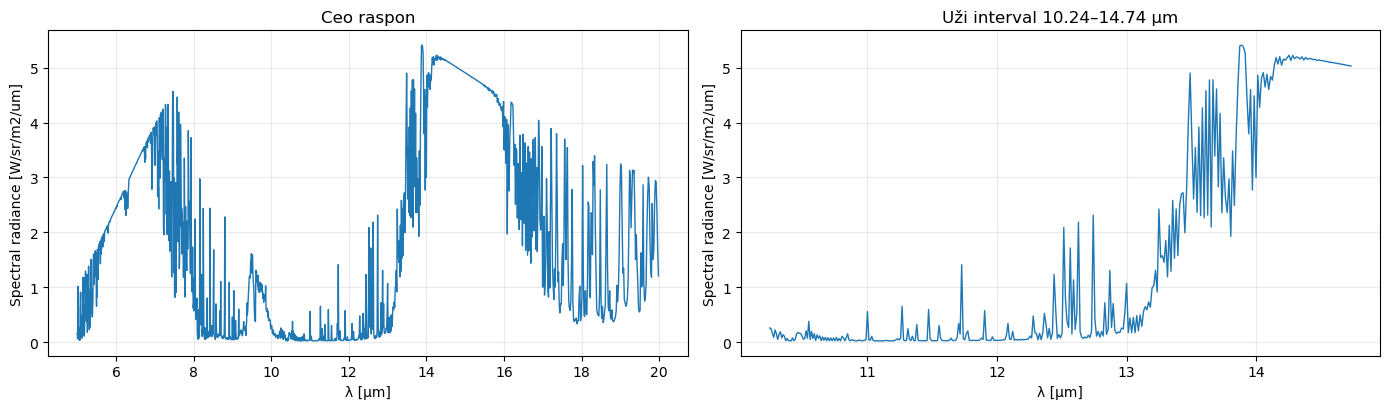

In [7]:
# ZADATAK 3 — učitavanje referentnog PSG izlaza, provera kolona i crtanje
def header_comments(lines):
    """Samo komentarske redove (#) — tu PSG obično navodi nazive kolona i jedinice."""
    return [l for l in lines if l.strip().startswith('#')]

def read_psg_numeric(path):
    """Tihi učitavač (bez štampanja zaglavlja) za kasnije fajlove."""
    rows = []
    for line in Path(path).read_text(encoding='utf-8-sig', errors='replace').splitlines():
        s = line.strip()
        if not s or s.startswith('#') or s.startswith('<'):
            continue
        try:
            rows.append([float(v.replace('D', 'E').replace('d', 'e')) for v in s.split()])
        except ValueError:
            continue
    return pd.DataFrame(rows, columns=[f'col_{i}' for i in range(len(rows[0]))])

def to_um(x, unit):
    x = np.asarray(x, float)
    if unit == 'um':   return x
    if unit == 'nm':   return x / 1e3
    if unit == 'cm-1': return 1e4 / x
    raise ValueError("X_UNIT mora biti 'um', 'nm' ili 'cm-1'")

X_COL  = 'col_0'
Y_COL  = 'col_1'
X_UNIT = 'um'
Y_LABEL = 'Spectral radiance [W/sr/m2/um]'

REF_TXT = next((p for p in [DATA_DIR/'earth_ref.txt', DATA_DIR/'earth_ref.rad', DATA_DIR/'earth_ref.dat'] if p.exists()), None)
if REF_TXT is None:
    print('Nema data/earth_ref.(txt|rad|dat) — izvezite ASCII iz PSG-a.')
else:
    df_ref, header_ref = inspect_psg_ascii(REF_TXT)
    print('\n--- Komentarski redovi zaglavlja (nazivi kolona/jedinice) ---')
    print('\n'.join(header_comments(header_ref)[:20]) or '(nema # redova — pogledajte originalni fajl)')

    if None in (X_COL, Y_COL, X_UNIT, Y_LABEL):
        print('\n>>> Postavite X_COL, Y_COL, X_UNIT i Y_LABEL iznad (na osnovu zaglavlja) i pokrenite ćeliju ponovo.')
    else:
        x_um = to_um(df_ref[X_COL], X_UNIT); y = df_ref[Y_COL].to_numpy(float)
        o = np.argsort(x_um); x_um, y = x_um[o], y[o]

        # provera protiv .cfg (opseg i rezolucija)
        if CFG_REF.exists():
            c = parse_cfg(CFG_REF)
            print('\n.cfg opseg/rezolucija:', {k: v for k, v in c.items() if k.startswith('GENERATOR-RANGE') or 'RESOLUTION' in k})
        print(f'Podaci: {x_um.min():.3f}–{x_um.max():.3f} µm, N = {len(x_um)}')

        fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
        ax[0].plot(x_um, y, lw=1); ax[0].set(xlabel='λ [µm]', ylabel=Y_LABEL, title='Ceo raspon')
        span = x_um.max() - x_um.min()
        ZOOM = (x_um.min() + 0.35*span, x_um.min() + 0.65*span)   # PROMENITE na interval od interesa
        s = (x_um >= ZOOM[0]) & (x_um <= ZOOM[1])
        ax[1].plot(x_um[s], y[s], lw=1); ax[1].set(xlabel='λ [µm]', ylabel=Y_LABEL, title=f'Uži interval {ZOOM[0]:.2f}–{ZOOM[1]:.2f} µm')
        for a in ax: a.grid(alpha=.25)
        # Primer obeležavanja KANDIDATA (zamenite sopstvenim intervalima iz podataka):
        # ax[0].axvspan(14.0, 16.0, color='orange', alpha=.2, label='kandidat: CO₂?')
        plt.tight_layout(); plt.show()       

#### Komentar studenta   
Spektar (5–20 µm) pokazuje nekoliko oblasti. Oko 10–12,5 µm radijansa je skoro nula (atmosferski prozor). Na ~9,5 µm uočava se uzak izdanak (~1,6 W/sr/m²/µm), kandidat za O₃ (pojas oko 9,6 µm). Od ~13 do ~16 µm radijansa raste do ~5,2 i ostaje skoro konstantna, kandidat za CO₂ (15 µm). Oko 6–8 µm i iznad 16 µm vidi se gusta linijska struktura, kandidat za H₂O (i CH₄ oko 7,7 µm). Ne tvrdim identifikaciju: pojasevi se preklapaju, a pogled je sa tla, pa su pojasevi svetli, a ne tamni.

## Zadatak 4 - Atmosferski scenario

1. Napravite kopiju referentnog podešavanja i promenite **samo CO₂**, npr. faktorsku promenu abundance koju model podržava. Zapišite tačnu vrednost i jedinicu **pre i posle**.
2. Potvrdite da li je promenjen željeni **vertikalni profil** ili samo nominalno polje u GUI-ju.
3. Ponovo generišite spektar uz **identičnu geometriju, opseg, instrument, jedinice i druge atmosferske parametre**.
4. Sačuvajte `earth_variant.cfg` i odgovarajući originalni ASCII izlaz `earth_variant.txt`.
5. Uporedite `.cfg` fajlove pomoću `compare_cfg`; ispitajte neočekivane promene i obrazložite ih. Ako se uz CO₂ promenio i drugi parametar, scenario označite kao **nepotpuno kontrolisan**.

**Predajte:** oba `.cfg`, opis kontrolisane promene i proveru profila. Ako nemate dozvoljen način za promenu CO₂, nemojte ručno izmišljati PSG izlaze.

In [8]:
# ZADATAK 4 — poređenje konfiguracija i kontrola promena
CFG_VAR = DATA_DIR / 'earth_variant.cfg'
if not (CFG_REF.exists() and CFG_VAR.exists()):
    print('Potrebni su data/earth_ref.cfg i data/earth_variant.cfg.')
else:
    print('=== Tekstualna razlika (compare_cfg) ===')
    compare_cfg(CFG_REF, CFG_VAR)

    cr, cv = parse_cfg(CFG_REF), parse_cfg(CFG_VAR)
    changed = [k for k in sorted(set(cr) | set(cv)) if cr.get(k) != cv.get(k)]
    print('\n=== Ključevi čija se vrednost razlikuje ===')
    rows = []
    for k in changed:
        a = ' | '.join(cr.get(k, ['(nema)'])); b = ' | '.join(cv.get(k, ['(nema)']))
        rows.append({'ključ': k, 'REF': a[:60], 'VARIJANTA': b[:60]})
    display(pd.DataFrame(rows))

    # Ključevi koji bi očekivano pratili promenu CO₂ (abundance, profili/slojevi, nazivi gasova)
    expected = [k for k in changed if any(t in k for t in ('ABUN', 'LAYERS', 'ATMOSPHERE-GAS', 'ATMOSPHERE-TYPE', 'ATMOSPHERE-UNIT'))]
    unexpected = [k for k in changed if k not in expected]
    print('Očekivano povezano sa gasom:', expected)
    print('PROVERITI (nije očigledno CO₂):', unexpected if unexpected else 'nema')
    if unexpected:
        print('>>> Ako neki od ovih ključeva nije posledica regeneracije profila, scenario označite kao NEPOTPUNO KONTROLISAN.')
    # Napomena: ako PSG regeneriše ATMOSPHERE-LAYERS, uporedite i sâm profil CO₂ (u GUI-ju ili u izvezenom profilu).

=== Tekstualna razlika (compare_cfg) ===
--- REFERENCE
+++ VARIANT
@@ -42,7 +42,7 @@
 <ATMOSPHERE-NGAS>8
 <ATMOSPHERE-GAS>H2O,CO2,O3,N2O,CO,CH4,O2,N2
 <ATMOSPHERE-TYPE>HIT[1],HIT[2],HIT[3],HIT[4],HIT[5],HIT[6],HIT[7],HIT[22]
-<ATMOSPHERE-ABUN>1,1,1,1,1,1,1,1
+<ATMOSPHERE-ABUN>1,5,1,1,1,1,1,1
 <ATMOSPHERE-UNIT>scl,scl,scl,scl,scl,scl,scl,scl
 <ATMOSPHERE-LAYERS-MOLECULES>H2O,CO2,O3,N2O,CO,CH4,O2,NO,SO2,NO2,NH3,HNO3,OH,HF,HCl,HBr,HI,ClO,OCS,H2CO,HOCl,N2,HCN,CH3Cl,H2O2,C2H2,C2H6,PH3,WaterIce
 <ATMOSPHERE-LAYERS>53
@@ -147,4 +147,19 @@
 <GEOMETRY-BRDFSCALER>1.0
 <GEOMETRY-TEMISSION>275.450
 <GEOMETRY-AZIMUTH>0.000
+<ATMOSPHERE-CLOUDFRACTION>1.0
+<ATMOSPHERE-AEROS>
+<ATMOSPHERE-ATYPE>
+<ATMOSPHERE-AABUN>
+<ATMOSPHERE-AUNIT>
+<ATMOSPHERE-ASIZE>
+<ATMOSPHERE-ASUNI>
+<ATMOSPHERE-CONTINUUM>Rayleigh,Refraction,CIA_all,UV_all
+<SURFACE-PHASEMODEL>ISO
+<SURFACE-MIXING>
+<SURFACE-SURF>
+<SURFACE-TYPE>
+<SURFACE-ABUN>
+<SURFACE-UNIT>
+<SURFACE-THICK>
 <GENERATOR-RESOLUTIONKERNEL>N

=== Ključevi čija

,ključ,REF,VARIJANTA
0,ATMOSPHERE-AABUN,(nema),
1,ATMOSPHERE-ABUN,"1,1,1,1,1,1,1,1","1,5,1,1,1,1,1,1"
2,ATMOSPHERE-AEROS,(nema),
3,ATMOSPHERE-ASIZE,(nema),
4,ATMOSPHERE-ASUNI,(nema),
5,ATMOSPHERE-ATYPE,(nema),
6,ATMOSPHERE-AUNIT,(nema),
7,ATMOSPHERE-CLOUDFRACTION,(nema),1.0
8,ATMOSPHERE-CONTINUUM,(nema),"Rayleigh,Refraction,CIA_all,UV_all"
9,SURFACE-ABUN,(nema),


Očekivano povezano sa gasom: ['ATMOSPHERE-AABUN', 'ATMOSPHERE-ABUN', 'SURFACE-ABUN']
PROVERITI (nije očigledno CO₂): ['ATMOSPHERE-AEROS', 'ATMOSPHERE-ASIZE', 'ATMOSPHERE-ASUNI', 'ATMOSPHERE-ATYPE', 'ATMOSPHERE-AUNIT', 'ATMOSPHERE-CLOUDFRACTION', 'ATMOSPHERE-CONTINUUM', 'SURFACE-MIXING', 'SURFACE-PHASEMODEL', 'SURFACE-SURF', 'SURFACE-THICK', 'SURFACE-TYPE', 'SURFACE-UNIT']
>>> Ako neki od ovih ključeva nije posledica regeneracije profila, scenario označite kao NEPOTPUNO KONTROLISAN.


## Zadatak 5 - Uporedite spektre i identifikujte atmosferske karakteristike 

1. Učitajte referentni i izmenjeni ASCII izlaz. Iz zaglavlja **nezavisno za svaki** potvrdite koordinatu i njenu jedinicu, tip veličine i jedinicu y-ose.
2. Na zajedničkom grafiku preklopite oba spektra. Ako spektralne mreže nisu identične, interpolirajte jedan spektar na drugi **samo u preseku domena** i navedite postupak.
3. Izračunajte $\Delta F=F_\mathrm{variant}-F_\mathrm{ref}$ i, samo gde je bezbedno, relativnu razliku.
4. Označite najmanje **tri spektralna intervala** od interesa i moguće molekule (ako opseg dozvoljava). Ako je posmatran samo jedan jasan interval, objasnite zašto nema drugih.
5. Za CO₂ objasnite da li se posmatrana promena uklapa u očekivanja. Obratite pažnju na saturaciju i temperaturni profil: „više CO₂ = dublja apsorpcija svuda“ nije univerzalno pravilo.

**Predajte:** preklopljene krive, grafik razlike i tabelu *interval–kandidat molekula–dokaz–ograničenje*.

Zaglavlje REFERENCE:
# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Thu Nov 26 12:57:05 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,0.00000,0.00000,-0.45260,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 2.359 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]

Zaglavlje VARIJANTE:
Fajl: earth_variant.txt; ukupno redova: 1400
--- PRVI REDOVI ---

--- DIMENZIJE --- (1387, 3)


,col_0,col_1,col_2
0,5.000000,0.158142,0.158142
1,5.005000,0.170810,0.170810
2,5.010005,0.067520,0.067520
3,5.015015,0.339384,0.339384
4,5.020030,1.018546,1.018550


# ------------------------------------------------------------------------
# Radiance spectrum
# NASA-GSFC Planetary Spectrum Generator (PSG) (Villanueva et al. 2018, 2022)
# Synthesized on Thu Nov 26 14:11:45 2026
# Doppler velocities [km/s] (vobs,vrot+vorb,vwidth,vrfl,vstr): 0.00000,0.00000,0.00000,-0.45260,0.00000
# ------------------------------------------------------------------------
# Spectra synthesized with the Planetary and Universal Model of Atmospheric Scattering (PUMAS, Villanueva et al. 2018, 2022)
# Single scattering radiative transfer method
# Radiative transfer took 2.381 seconds
# ------------------------------------------------------------------------
# Spectral unit: Wavelength [um]
# Radiance unit: Spectral radiance [W/sr/m2/um]

Mreže identične: True; presek domena 5.000–19.980 µm; N = 1387


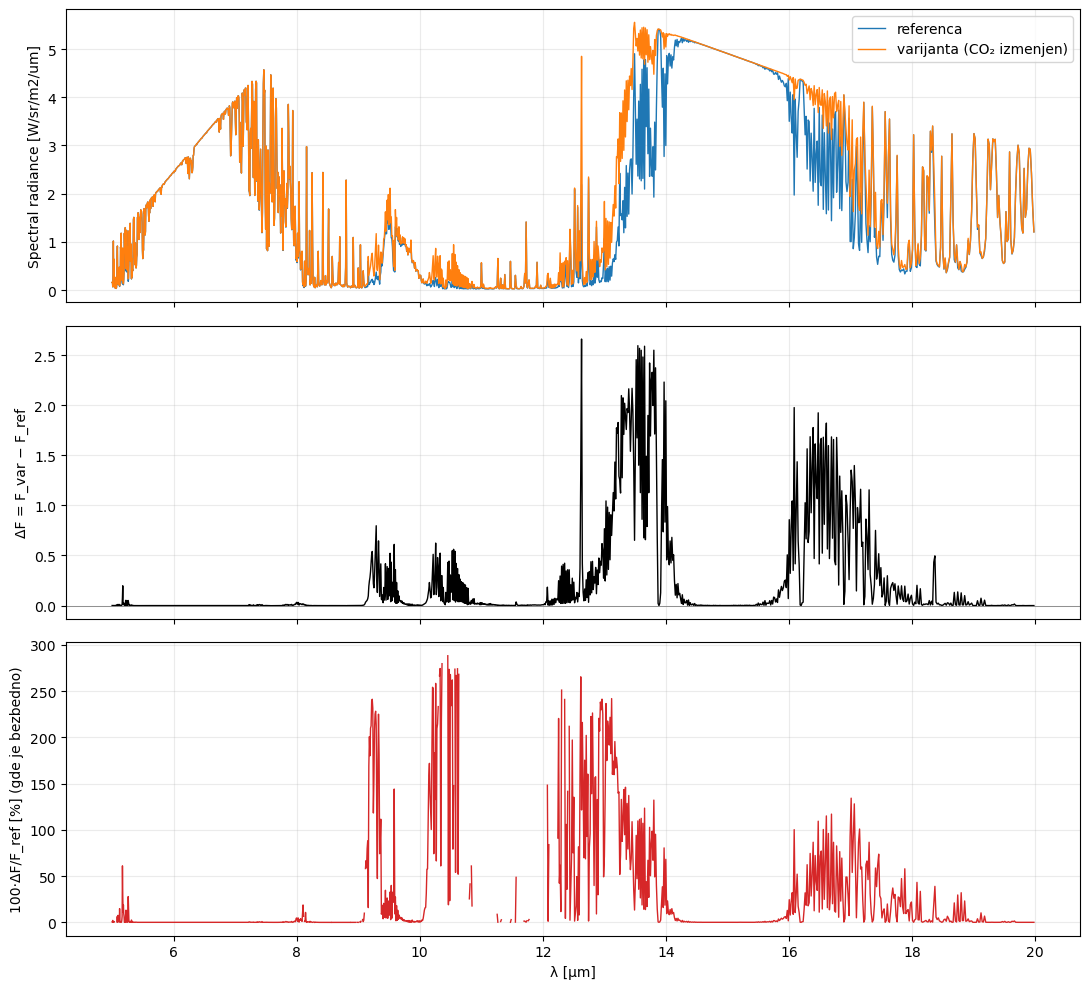

Najveće |ΔF| (izgl. kandidati za proveru): [9.292, 10.341, 13.45, 16.508] µm
Popunite CANDIDATES (najmanje tri intervala, ili obrazložite zašto ih nema) i pokrenite ponovo.


In [9]:
# ZADATAK 5 — učitavanje oba stvarna PSG spektra i poređenje
from scipy.signal import find_peaks

VAR_TXT = next((p for p in [DATA_DIR/'earth_variant.txt', DATA_DIR/'earth_variant.rad', DATA_DIR/'earth_variant.dat'] if p.exists()), None)

# Ako se kolone/jedinice varijante razlikuju od reference, postavite posebno (potvrda iz njenog zaglavlja!)
X_COL_V, Y_COL_V, X_UNIT_V = None, None, None   # None = isto kao za referencu (samo ako ste to proverili u zaglavlju)

# Spektralni intervali od interesa: (λ_min, λ_max, 'kandidat molekula') — popunite iz SVOJIH podataka
CANDIDATES = [
    # (14.0, 16.0, 'CO2?'),
    # (9.2, 10.0, 'O3?'),
    # (5.5, 7.5, 'H2O?'),
]

if REF_TXT is None or VAR_TXT is None or None in (X_COL, Y_COL, X_UNIT):
    print('Potrebno: earth_ref i earth_variant ASCII u data/ i podešene X_COL/Y_COL/X_UNIT iz Zadatka 3.')
else:
    print('Zaglavlje REFERENCE:'); print('\n'.join(header_comments(header_ref)[:12]))
    print('\nZaglavlje VARIJANTE:')
    _, header_var = inspect_psg_ascii(VAR_TXT, preview_lines=0)
    print('\n'.join(header_comments(header_var)[:12]))
    df_var = read_psg_numeric(VAR_TXT)

    xc_v, yc_v, xu_v = (X_COL_V or X_COL), (Y_COL_V or Y_COL), (X_UNIT_V or X_UNIT)
    def prep(df, xc, yc, xu):
        x = to_um(df[xc], xu); y = df[yc].to_numpy(float); o = np.argsort(x); return x[o], y[o]
    xr, yr = prep(df_ref, X_COL, Y_COL, X_UNIT)
    xv, yv = prep(df_var, xc_v, yc_v, xu_v)

    # zajednička mreža: preseku domena, bez ekstrapolacije; varijanta se linearno interpolira na mrežu reference
    lo, hi = max(xr.min(), xv.min()), min(xr.max(), xv.max())
    m = (xr >= lo) & (xr <= hi)
    x, F1 = xr[m], yr[m]
    same = len(xr) == len(xv) and np.allclose(xr, xv)
    F2 = yv[(xv >= lo) & (xv <= hi)] if same else np.interp(x, xv, yv)
    print(f'\nMreže identične: {same}; presek domena {lo:.3f}–{hi:.3f} µm; N = {len(x)}'
          + ('' if same else ' (varijanta linearno interpolirana na mrežu reference)'))

    dF = F2 - F1
    safe = np.abs(F1) > 0.01 * np.nanmax(np.abs(F1))       # relativna razlika samo gde F1 nije ≈ 0
    rel = np.full_like(dF, np.nan); rel[safe] = 100 * dF[safe] / F1[safe]

    fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    ax[0].plot(x, F1, lw=1, label='referenca'); ax[0].plot(x, F2, lw=1, label='varijanta (CO₂ izmenjen)')
    ax[0].set_ylabel(Y_LABEL); ax[0].legend()
    ax[1].plot(x, dF, lw=1, c='k'); ax[1].axhline(0, c='gray', lw=.6); ax[1].set_ylabel('ΔF = F_var − F_ref')
    ax[2].plot(x, rel, lw=1, c='tab:red'); ax[2].set_ylabel('100·ΔF/F_ref [%] (gde je bezbedno)'); ax[2].set_xlabel('λ [µm]')
    for (a_, b_, lab) in CANDIDATES:
        for a in ax: a.axvspan(a_, b_, alpha=.15, color='orange')
        ax[0].text((a_+b_)/2, ax[0].get_ylim()[1], lab, ha='center', va='top', fontsize=9)
    for a in ax: a.grid(alpha=.25)
    plt.tight_layout(); plt.show()

    # Sugestija (NE identifikacija): gde je |ΔF| najveća — to su mesta koja vredi uporediti sa tabelom molekula
    k = max(5, len(x)//50)
    sm = np.convolve(np.abs(dF), np.ones(k)/k, mode='same')
    pk, _ = find_peaks(sm, distance=max(1, len(x)//20), prominence=np.nanmax(sm)*0.1)
    top = pk[np.argsort(sm[pk])[::-1][:5]]
    print('Najveće |ΔF| (izgl. kandidati za proveru):', [round(float(x[i]), 3) for i in sorted(top)], 'µm')

    # Tabela za interval-kandidat-dokaz
    if CANDIDATES:
        rows = []
        for a_, b_, lab in CANDIDATES:
            s = (x >= a_) & (x <= b_)
            rows.append({'interval [µm]': f'{a_}–{b_}', 'kandidat': lab,
                         'ref: min': F1[s].min(), 'var: min': F2[s].min(),
                         'srednje ΔF': dF[s].mean(), 'min ΔF': dF[s].min(), 'max ΔF': dF[s].max()})
        display(pd.DataFrame(rows))
    else:
        print('Popunite CANDIDATES (najmanje tri intervala, ili obrazložite zašto ih nema) i pokrenite ponovo.')

### Komentar studenta - Zadatak 5 

#### Preklapanje spektara
Grafikon je napravljen sa:
- referentnim spektrom (plava linija);
- izmenjenim spektrom (narandžasta linija);
- donjim panelom koji prikazuje razliku između spektara.
Najvažnije zapažanje je da se spektri uglavnom dobro poklapaju, ali postoje značajne razlike u određenim oblastima, naročito između 12,5–14 µm i 16–17,2 µm.

#### Razlika između spektara
Računamo:

$\Delta F=F_{\mathrm{variant}}-F_{\mathrm{ref}}$

Relativna razlika je:

$\frac{\Delta F}{F_{\mathrm{ref}}}\cdot100\%$

Relativnu razliku ne treba računati u oblastima gde je referentna radijansa veoma blizu nule, jer tada rezultat postaje numerički nestabilan.

Uočavamo:
- Oko 6,3 µm razlika je zanemarljiva.
- Oko 7,7 µm takođe nema značajne promene.
- Oko 9,6 µm izmenjeni spektar pokazuje povećanje radijanse.
- Između 12,5 i 14 µm javlja se veoma značajno povećanje.
- Između 14 i 16 µm spektri se ponovo veoma dobro poklapaju.
- Između 16 i 17,2 µm ponovo postoji značajno povećanje radijanse.

#### Identifikacija spektralnih intervala
| Talasna dužina | Molekul | Karakteristika |
|---|---|---|
| Oko 6,3 µm | H₂O | Apsorpciona traka vodene pare |
| Oko 7,7 µm | CH₄ | Apsorpciona traka metana |
| Oko 9,6 µm | O₃ | Apsorpciona traka ozona |
| Oko 15 µm | CO₂ | Široka i izražena apsorpciona traka ugljen-dioksida |

#### Promena koncentracije CO₂
Najvažnija karakteristika ovog poređenja jeste ponašanje široke apsorpcione trake CO₂ oko 15 µm.

Primećujemo da se spektri značajno razlikuju na rubovima ove trake, naročito između 12,5–14 µm i 16–17,2 µm, dok se u centralnoj oblasti između 14 i 16 µm uglavnom poklapaju.

Ovo je važno zbog pojave saturacije apsorpcione trake. U njenom centralnom delu apsorpcija je već veoma jaka, pa dodatno povećanje koncentracije CO₂ ne mora značajno da promeni izmerenu radijansu. Međutim, na rubovima apsorpcione trake dodatna količina CO₂ može povećati apsorpciju i proširiti oblast u kojoj je ona izražena.


## Reference i alati

- [NASA PSG — početna strana](https://psg.gsfc.nasa.gov/)
- [NASA PSG — uputstvo za rad i konfiguracije](https://psg.gsfc.nasa.gov/help.php)
- [NASA PSG — atmosferski profili i jedinice](https://psg.gsfc.nasa.gov/helpatm.php)
- [NASA PSG — API i tipovi ASCII izlaza](https://psg.gsfc.nasa.gov/helpapi.php)
- [NASA PSG — priručnik](https://psg.gsfc.nasa.gov/images/help/handbook.pdf)
